## Implementation of Linear regression using python

In [17]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt


## Load the dataset

In [19]:
DF1=pd.read_csv("weight-height.csv")
DF1.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


### Standardize numerical features

In [20]:
col=["Height", "Weight"]
S1=MinMaxScaler()
DF1[col]=S1.fit_transform(DF1[col])
DF1.head()

,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [24]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
X.shape
Y.shape

(10000, 1)

## Split the data into training and test set

In [33]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [34]:
# Create a linear regression model

model=LinearRegression()



Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [35]:
## Training  Linear regressions model 

In [36]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [37]:
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.0044380478890117024
0.06661867522708405
0.054480150433493836
0.8135299373473699
[3.54709605]
[0.10829265]


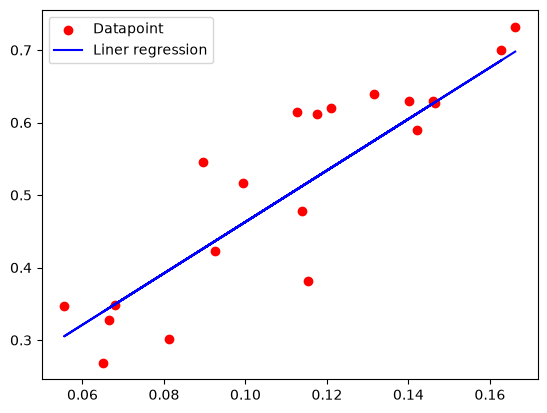

In [38]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [38]:
## Load the Height and weight  to indipendent and dependent variable 

In [42]:
df2=pd.read_csv("weight-height.csv")
X=df2['Height'].values.reshape(-1,1)
X.shape
Y=df2['Weight'].values
print(X.shape)
print(Y.shape)

(10000, 1)
(10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [62]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


C:\Users\USER\AppData\Local\Temp\ipykernel_13640\998710440.py:2: RuntimeWarning: invalid value encountered in divide
  X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [60]:
#add another feature to X corresponding to bias
X=np.hstack((np.ones((X.shape[0],1)), X))
X

array([[ 1.        ,  1.        ,  1.        , ...,         nan,
                nan,  1.75827913],
       [ 1.        ,  1.        ,  1.        , ...,         nan,
                nan,  0.56277158],
       [ 1.        ,  1.        ,  1.        , ...,         nan,
                nan,  1.82037531],
       ...,
       [ 1.        ,  1.        ,  1.        , ...,         nan,
                nan, -0.59704831],
       [ 1.        ,  1.        ,  1.        , ...,         nan,
                nan, 24.22511229],
       [ 1.        ,  1.        ,  1.        , ...,         nan,
                nan, -1.05110595]], shape=(10000, 8))

In [69]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)


(10000, 8)
(8, 10000)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [19]:
import numpy as np
import matplotlib.pyplot as plt

X_raw = X.values.astype(float)        # features only, NO bias column yet
Y = y.values.astype(float).ravel()       # flat 1D target, shape (1000,)

mu = X_raw.mean(axis=0)
sigma = X_raw.std(axis=0)
sigma[sigma == 0] = 1                    # guard against divide-by-zero
X_norm = (X_raw - mu) / sigma

X = np.c_[np.ones(len(X_norm)), X_norm]  # add bias column AFTER normalizing
theta = np.zeros(X.shape[1])

In [20]:
print("X:", X.shape, "Y:", Y.shape, "theta:", theta.shape)
print("NaNs in X:", np.isnan(X).sum(), "| NaNs in Y:", np.isnan(Y).sum())
print("Prediction shape:", np.dot(X, theta).shape)

X: (1000, 8) Y: (1000,) theta: (8,)
NaNs in X: 0 | NaNs in Y: 0
Prediction shape: (1000,)


In [21]:
learningrate = 0.1
iterations = 1000
mseh = []                                # reset, or old values pile up

for i in range(iterations):
    y_pred = X @ theta
    mse = np.mean((y_pred - Y) ** 2)     # no sklearn, so no validation errors
    mseh.append(mse)
    gradient = X.T @ (y_pred - Y) / len(Y)
    theta = theta - learningrate * gradient
    if (i + 1) % 100 == 0:
        print(f"iteration {i+1}: MSE = {mse:.4f}")

iteration 100: MSE = 113.1611
iteration 200: MSE = 113.1611
iteration 300: MSE = 113.1611
iteration 400: MSE = 113.1611
iteration 500: MSE = 113.1611
iteration 600: MSE = 113.1611
iteration 700: MSE = 113.1611
iteration 800: MSE = 113.1611
iteration 900: MSE = 113.1611
iteration 1000: MSE = 113.1611


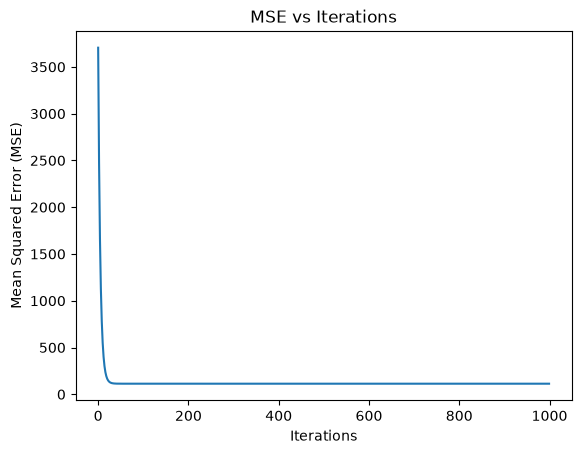

In [22]:
plt.plot(range(iterations), mseh)
plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("MSE vs Iterations")
plt.show()

In [23]:
print(theta)

[56.732      17.05959792  7.02689102  4.2780814   2.30007033  1.84119468
  2.76051056  0.50334157]


## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
df = pd.read_csv("Food_delivery_times.csv")
print(df.head())

   Order_ID  Distance_km Weather Traffic_Level Time_of_Day Vehicle_Type  \
0       522         7.93   Windy           Low   Afternoon      Scooter   
1       738        16.42   Clear        Medium     Evening         Bike   
2       741         9.52   Foggy           Low       Night      Scooter   
3       661         7.44   Rainy        Medium   Afternoon      Scooter   
4       412        19.03   Clear           Low     Morning         Bike   

   Preparation_Time_min  Courier_Experience_yrs  Delivery_Time_min  
0                    12                     1.0                 43  
1                    20                     2.0                 84  
2                    28                     1.0                 59  
3                     5                     1.0                 37  
4                    16                     5.0                 68  


In [6]:
df = df[["Distance_km", "Preparation_Time_min", "Traffic_Level", "Weather", "Delivery_Time_min"]]

In [7]:
df["Distance_km"] = df["Distance_km"].fillna(df["Distance_km"].median())
df["Preparation_Time_min"] = df["Preparation_Time_min"].fillna(df["Preparation_Time_min"].median())
df["Traffic_Level"] = df["Traffic_Level"].fillna(df["Traffic_Level"].mode()[0])
df["Weather"] = df["Weather"].fillna(df["Weather"].mode()[0])
df = df.dropna(subset=["Delivery_Time_min"])

In [8]:
traffic_map = {"Low": 1, "Medium": 2, "High": 3}
df["Traffic_Level"] = df["Traffic_Level"].map(traffic_map)

In [9]:
df = pd.get_dummies(df, columns=["Weather"], drop_first=True, dtype=int)
print(df.head())

   Distance_km  Preparation_Time_min  Traffic_Level  Delivery_Time_min  \
0         7.93                    12              1                 43   
1        16.42                    20              2                 84   
2         9.52                    28              1                 59   
3         7.44                     5              2                 37   
4        19.03                    16              1                 68   

   Weather_Foggy  Weather_Rainy  Weather_Snowy  Weather_Windy  
0              0              0              0              1  
1              0              0              0              0  
2              1              0              0              0  
3              0              1              0              0  
4              0              0              0              0  


In [10]:
X = df.drop("Delivery_Time_min", axis=1)
y = df["Delivery_Time_min"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[3. ,0.99,5.42,...,4.43,9.37,1.18]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Distance_km','Preparation_Time_min','Traffic_Level',...,'Weather_Rainy', 'Weather_Snowy','Weather_Windy']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.471
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [13]:
print("Intercept:", model.intercept_)
coef_df = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_})
print(coef_df)

Intercept: -2.4708580450418793
                Feature  Coefficient
0           Distance_km     2.997541
1  Preparation_Time_min     0.988672
2         Traffic_Level     5.419439
3         Weather_Foggy     6.054762
4         Weather_Rainy     4.431181
5         Weather_Snowy     9.369923
6         Weather_Windy     1.175243


In [16]:
y_pred = model.predict(X_test)
print("R² Score:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R² Score: 0.8225545150844052
MSE: 79.53585293112515
RMSE: 8.918287555978734


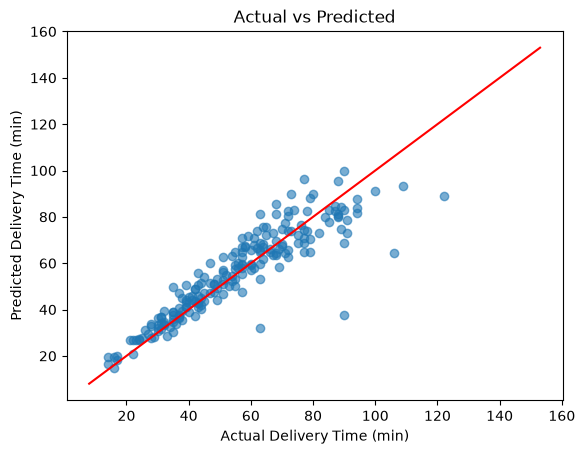

In [17]:
import matplotlib.pyplot as plt
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red")
plt.xlabel("Actual Delivery Time (min)")
plt.ylabel("Predicted Delivery Time (min)")
plt.title("Actual vs Predicted")
plt.show()